<a href="https://colab.research.google.com/github/FOFM030711/SIMULACION-II/blob/main/MB_DerivaSD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# <font color="#742D2B">MOVIMIENTO BROWNIANO</font>

<font color="#742D2B">29 de octubre de 2026</font>

**Alumna:** Florencio Florencio Miriam Lizeth




**Objetivo:** Observar cómo el movimiento browniano combina una tendencia creciente con fluctuaciones aleatorias y cómo podemos utilizar sus trayectorias para estimar probabilidades y compararlas con los resultados teóricos.

**Movimiento Browniano**
 Un proceso estocástico $(W(t))$ para $(t \in [0,T])$ se llama movimiento Browniano o proceso estándar de Wiener si satisface las siguientes condiciones:


*  $(C_1): (W(0) = 0)$
* $(C_2):Para (0 \leq s \leq t \leq T)$, la variable aleatoria dada por el incremento $(W(t) - W(s))$ es $(N(0, t-s))$; equivalentemente,

    W(t) - W(s) \sim \sqrt{t-s} \, N(0,1)

* $(C_3)$: Para $(0 \leq s \leq t \leq u \leq v \leq T)$, los incrementos (W(t) - W(s))$ y $(W(v) - W(u))$ son independientes.

*Seudocódigo*

1. $dt=\frac{T}{L}$
2. $W_0=0$
3. Para $i=0$ a $L-1$
4. Calcule un $\xi_i\sim N (0,1)$
5. $W_{i+1}=W_i+ \sqrt {dt}\xi _1$
6. Terminar



---



---

**Ejercicio:**  Encuentre la probabilidad de que el **MB** con parametro $μ=0.6$ y $σ^2=0.25 $  tome valores entre $1$ y $3$ al tiempo $t=4$

**SOLUCION ANALITICA** (Realizada en clase):



$$X_t &= 0.6t + 0.5B_t$$

$$P(1 < X_4 < 3) &= P(1 < 2.4 + \frac{1}{2}B_4 < 3)$$

$$= P(-1.4 < \frac{1}{2}B_4 < 0.6)$$
$$= P(-2.8 < B_4 < 1.2)$$
$$= \int_{-2.8}^{1.2} \frac{1}{\sqrt{2(4)\pi}} e^{-\frac{x^2}{8}} \, dx$$


Realizamos el cambio de variable:
$$
z=\frac{x}{2},
\qquad dx=2\,dz.
$$


Los nuevos límites son:
$$
z_1=\frac{-2.8}{2}=-1.4,
\qquad
z_2=\frac{1.2}{2}=0.6.
$$

Sustituyendo en la integral:
$$P(-2.8 \leq X \leq 1.2)$$
$$= \int_{-1.4}^{0.6}
\frac{1}{2\sqrt{2\pi}}
e^{-\frac{(2z)^2}{8}}(2)\,dz$$

$$= \int_{-1.4}^{0.6}
\frac{1}{\sqrt{2\pi}}
e^{-\frac{z^2}{2}}\,dz$$

$$= \Phi(0.6)-\Phi(-1.4)$$

$$= 0.7257469-0.0807567$$

$$= 0.6449902$$

$$\boxed{\approx 0.6450}.
$$






---

**SOLUCION ANALITICA** (Otro modo de resolverlo):

Trabajaremos bajo el supuesto de que se trata de un movimiento Browniano con deriva, definido por
$$
X(t)=\mu t+\sigma W(t),
$$

donde $(W(t))$ es un movimiento Browniano estándar, $(\mu)$ es la deriva y $(\sigma^2)$ es la varianza por unidad de tiempo.
.
$$
\mu=0.6,\qquad \sigma^2=0.25,\qquad t=4.
$$

Además, queremos calcular:
$$
\boxed{P(1<X(4)<3)}
$$

Sustituimos los valores del ejercicio.

Media:
$$
\mathbb{E}[X(4)]=(0.6)(4)=2.4.
$$

Varianza:
$$
\operatorname{Var}(X(4))=(0.25)(4)=1.
$$

Por lo tanto, la distribución en el tiempo \(t=4\) es
$$
\boxed{X(4)\sim\mathcal{N}(2.4,1)}.
$$

La desviación estándar es
$$
\sigma_4=\sqrt{1}=1.
$$


Queremos encontrar
$$
P(1<X(4)<3).
$$

Estandarizamos mediante la transformación
$$
Z=\frac{X(4)-2.4}{1},
$$

donde $(Z\sim\mathcal{N}(0,1))$.

Aplicando la transformación a los dos límites:
$$
P\left(\frac{1-2.4}{1}<Z<
\frac{3-2.4}{1}\right).
$$

Simplificando:
$$
\boxed{P(-1.4<Z<0.6)}.
$$

Ahora, utilizar la función de distribución normal estándar.

Denotamos por $(\Phi(z))$ la función de distribución acumulada de una normal estándar. Entonces,
$$
P(-1.4<Z<0.6)=\Phi(0.6)-\Phi(-1.4).
$$

Consultando la tabla de la normal estándar, obtenemos aproximadamente:
$$
\Phi(0.6)=0.7257
$$

$$
\Phi(-1.4)=0.0808.
$$

Por lo tanto,
$$
P(1<X(4)<3)=0.7257-0.0808.
$$

El resultado es
$$
\boxed{P(1<X(4)<3)\approx0.6450}.
$$

En porcentaje, la probabilidad es aproximadamente 64.50 %.


**En este ejercicio, $(\sigma=\sqrt{0.25}=0.5)$, $T=4$ y elegiremos $L=1000$pasos.**

In [1]:
# Librerias
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


In [23]:
#     Trayectoria del MB estándar en [0,T] con n pasos (devuelve n+1 puntos, W_0 = 0).
def brown(T, n):

    dt = T / n
    w_0 = 0
    lista = [w_0]
    for i in range(n):
        dw = r.gauss(0, 1)
        w_1 = w_0 + np.sqrt(dt) * dw
        lista.append(w_1)
        w_0 = w_1
    return lista

In [24]:
def tiempos(T, n):
    return np.linspace(0, T, n + 1)

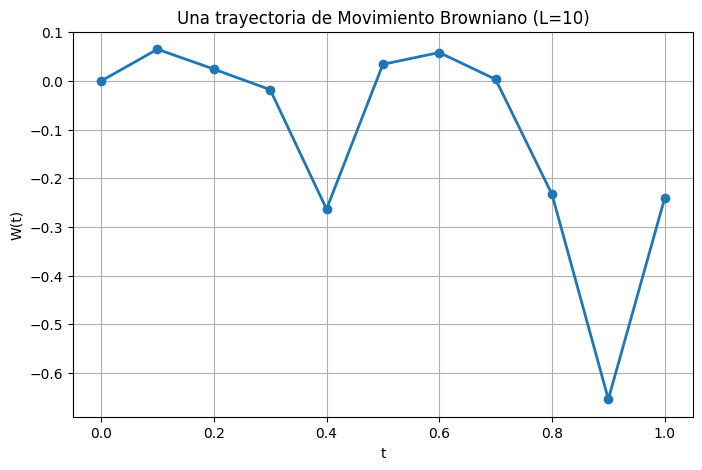

In [22]:
T, L = 1, 10 #Ejemplo de como usar
M = brown(T, L)
plt.figure(figsize=(8, 5))
plt.plot(tiempos(T, L), M, 'o-', lw=2)
plt.title("Una trayectoria de Movimiento Browniano (L=10)")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.grid(True)
plt.show()

Probabilidad Monte Carlo: 0.55
Probabilidad teórica: 0.6449902230161554
Error absoluto: 0.09499022301615534


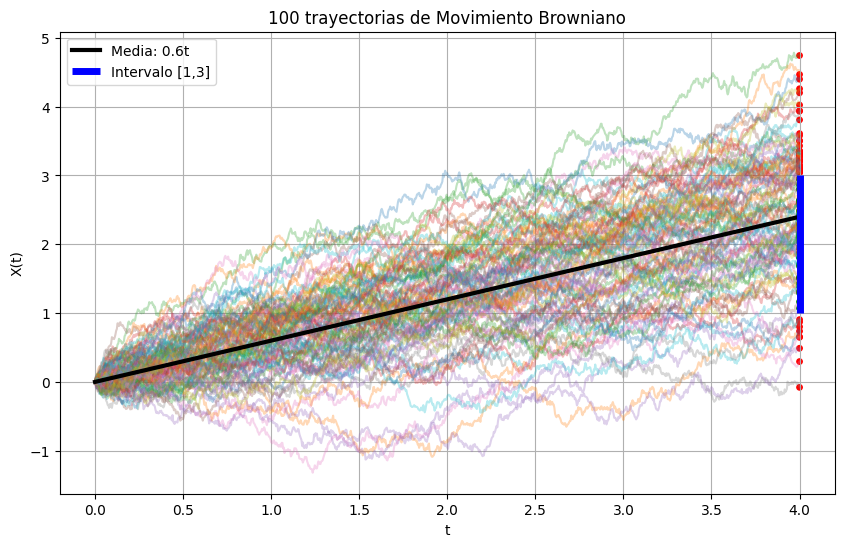

In [25]:

# Parámetros de nuestro ejercicio
T = 4
L = 1000
N = 100

mu = 0.6
sigma = np.sqrt(0.25)

dt = T / L
t = np.linspace(0, T, L + 1)

# Incrementos gaussianos
dW = np.sqrt(dt) * np.random.randn(N, L)

# Trayectorias brownianas
W = np.cumsum(dW, axis=1)

# Agregar W0 = 0
W = np.column_stack((np.zeros(N), W))

# Movimiento browniano con deriva
X = mu * t + sigma * W

# Valores al tiempo t = 4
X_final = X[:, -1]

# Probabilidad mediante Monte Carlo
exitos = np.sum((X_final >= 1) & (X_final <= 3))
prob_MC = exitos / N

# Probabilidad teórica
media = mu * T
desv = sigma * np.sqrt(T)

prob_teorica = norm.cdf(3, media, desv) - norm.cdf(1, media, desv)

print("Probabilidad Monte Carlo:", prob_MC)
print("Probabilidad teórica:", prob_teorica)
print("Error absoluto:", abs(prob_teorica - prob_MC))

# Gráfica
plt.figure(figsize=(10, 6))

for k in range(N):
    plt.plot(t, X[k], alpha=0.3)

# Límites del intervalo
plt.scatter(
    np.full(N, T), X_final,
    c=np.where((X_final >= 1) & (X_final <= 3), 'green', 'red'),
    s=15
)

plt.plot(t, mu*t, 'k', lw=3, label='Media: 0.6t')

plt.vlines(T, 1, 3, colors='blue', lw=5,
           label='Intervalo [1,3]')

plt.title("100 trayectorias de Movimiento Browniano")
plt.xlabel("t")
plt.ylabel("X(t)")
plt.legend()
plt.grid(True)
plt.show()


En esta gráfica podemos observar cómo el movimiento browniano combina una tendencia creciente con fluctuaciones aleatorias y cómo podemos utilizar sus trayectorias para estimar probabilidades y compararlas con los resultados teóricos.

## <span style="color:teal;">**Refinamiento de una trayectoria**</span>

Dada una trayectoria con $n$ pasos de tamaño $\Delta=T/n$, se inserta un punto en el medio de cada intervalo:

$$W_{mid}=\frac{W_{t_i}+W_{t_{i+1}}}{2}+\frac{1}{2}\sqrt{\Delta}\;Z,\qquad Z\sim N(0,1)$$

Así la trayectoria conserva sus puntos originales y pasa a tener $2n$ pasos (de tamaño $\Delta/2$).

In [17]:
def ref(lista, T):
    """Refina una trayectoria del MB en [0,T]: inserta un punto medio en cada intervalo."""
    n = len(lista) - 1            # número de pasos
    dt = np.sqrt(T / n)           # raíz del tamaño de paso actual
    nueva = []
    for i in range(n):
        dw = r.gauss(0, 1)
        w_i = 1/2 * (lista[i] + lista[i+1]) + 1/2 * dw * dt
        nueva.append(lista[i])
        nueva.append(w_i)
    nueva.append(lista[-1])
    return nueva

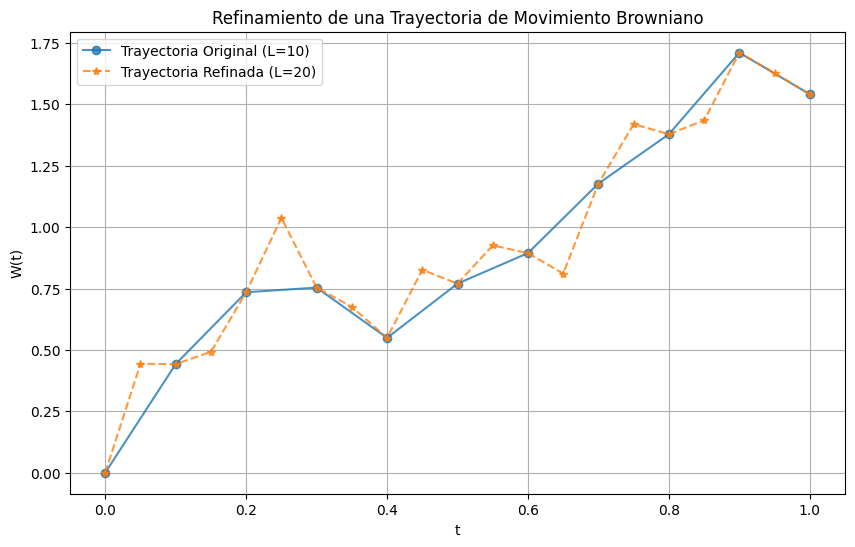

In [19]:
import random as r

# Definimos las funciones faltantes para la trayectoria estándar y los tiempos
def brown(T, L):
    dt = T / L
    # Genera una trayectoria de Movimiento Browniano estándar iniciando en 0
    dW = np.sqrt(dt) * np.random.randn(L)
    W = np.zeros(L + 1)
    W[1:] = np.cumsum(dW)
    return W

def tiempos(T, L):
    return np.linspace(0, T, L + 1)

T = 1
L = 10
W_orig = brown(T, L)              # trayectoria original con L=10 pasos
W_ref = ref(W_orig, T)            # trayectoria refinada con 2L=20 pasos

plt.figure(figsize=(10, 6))
plt.plot(tiempos(T, L), W_orig, 'o-', ms=6, alpha=0.8, label=f"Trayectoria Original (L={L})")
plt.plot(tiempos(T, 2*L), W_ref, '*--', ms=6, alpha=0.8, label=f"Trayectoria Refinada (L={2*L})")
plt.title("Refinamiento de una Trayectoria de Movimiento Browniano")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.legend(); plt.grid(True)
plt.show()

Agregamos el Puente Browviano definido como:

$$
X_{t}=B_t -tB_1 \quad , \quad 0 ≤t≤1
$$

Obviamente
$$X_0=0 \quad , \quad X_1=0 \quad E(X_t)= cov(X_t,X_s)$$

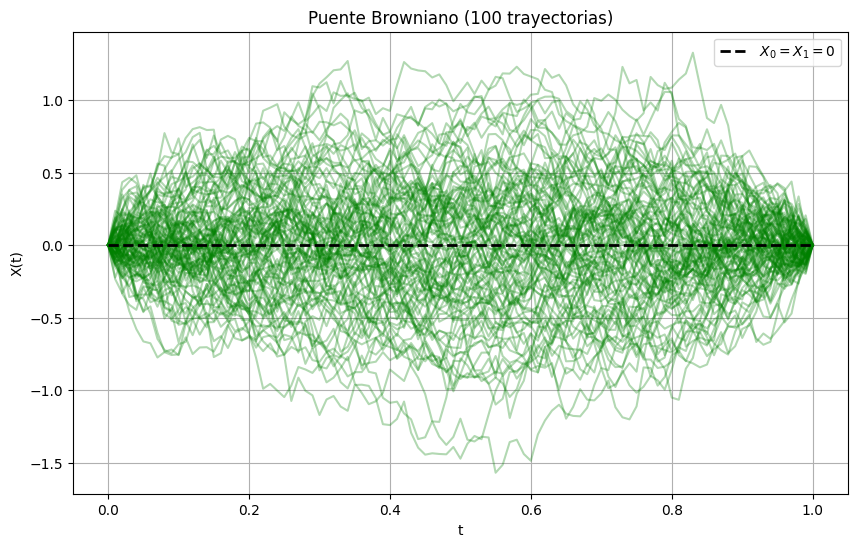

In [20]:

def puente(T, n):
    """Puente Browniano X_t = B_t - (t/T) B_T  (para T=1 es B_t - t B_1)."""
    B = np.array(brown(T, n))
    t = tiempos(T, n)
    return B - (t / T) * B[-1]

T, L, N = 1, 100, 100
t = tiempos(T, L)
plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, puente(T, L), alpha=0.3, color='green')
plt.plot(t, np.zeros_like(t), 'k--', lw=2, label='$X_0 = X_1 = 0$')
plt.title("Puente Browniano (100 trayectorias)")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

<span style="color:teal;">**Puente Browniano $X_t = B_t - t·B_1$**</span>

* Siempre comienza en 0 y termina en 0 en $t=1$
* Se obtiene restando a cada trayectoria Browniana el valor final multiplicado por t
* Útil para simular procesos condicionados a valores iniciales y finales


---



---
Usando el movimiento Browviano Deriva:
$$
X_t= \mu t + σB_t \quad , \quad t \geq0
$$
 para $$\mu ϵ R \quad y \quad σ>0$$


In [2]:
def deriva(mu, sigma, T, n):
    L = 1000
    dt = T / L
    t = np.linspace(0, T, L + 1)

    # Simular N caminatas con deriva
    Z = np.random.normal(0, 1, (n, L))
    incrementos = mu * dt + sigma * np.sqrt(dt) * Z
    X = np.zeros((n, L + 1))
    X[:, 1:] = np.cumsum(incrementos, axis=1)

    # Registrar X_T y calcular P = M/N
    XT = X[:, -1]
    M = np.sum((XT >= 1) & (XT <= 3))
    P = M / n

    # Probabilidad analítica
    Pa = norm.cdf(3, loc=mu*T, scale=sigma*np.sqrt(T)) - \
         norm.cdf(1, loc=mu*T, scale=sigma*np.sqrt(T))

In [3]:
# Parámetros del ejercicio
mu_val = 0.6
sigma_val = np.sqrt(0.25)
T_val = 4

# Definición de variables necesarias para la gráfica
media = mu_val * T_val
desviacion = sigma_val * np.sqrt(T_val)
a, b = 1, 3

# Intentar usar la probabilidad simulada si existe, de lo contrario usar la teórica
try:
    P = P_con_deriva
except NameError:
    P = norm.cdf(b, loc=media, scale=desviacion) - norm.cdf(a, loc=media, scale=desviacion)

sigma2 = sigma_val ** 2  # Varianza

# Curva de campana
x = np.linspace(media - 4*desviacion,
                media + 4*desviacion, 1000)
y = norm.pdf(x, loc=media, scale=desviacion)



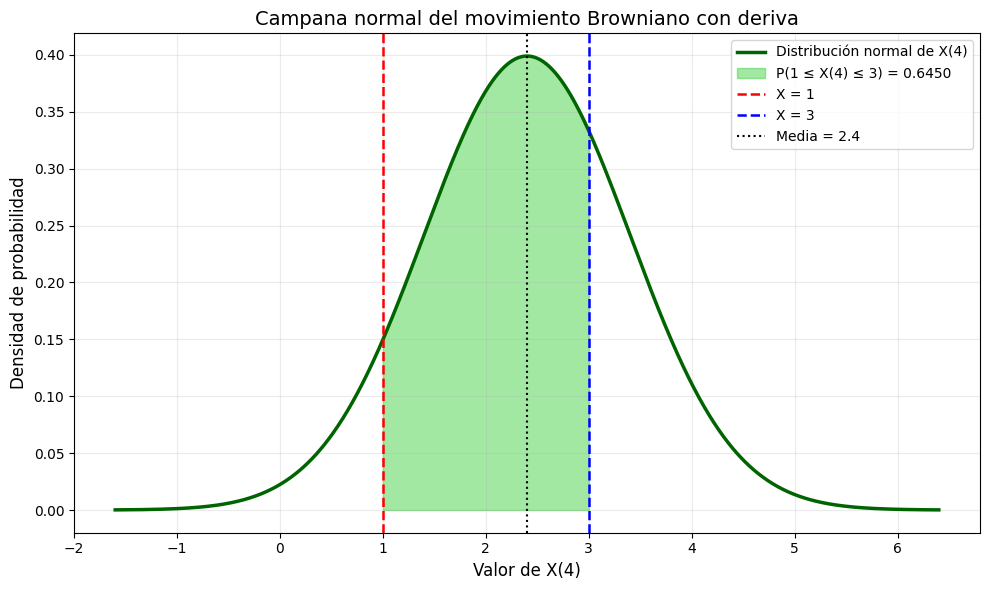

Media: 2.40
Varianza: 1.00
Probabilidad: 0.6450
Porcentaje: 64.50%


In [4]:
# Crear gráfica
plt.figure(figsize=(10, 6))

# Campana normal
plt.plot(x, y, color="darkgreen", linewidth=2.5,
         label="Distribución normal de X(4)")

# Sombrear el intervalo [1, 3]
x_sombra = np.linspace(a, b, 400)
y_sombra = norm.pdf(x_sombra, loc=media,
                    scale=desviacion)

plt.fill_between(x_sombra, y_sombra, color="limegreen",
                 alpha=0.45,
                 label=f"P(1 ≤ X(4) ≤ 3) = {P:.4f}")

# Límites del intervalo
plt.axvline(a, color="red", linestyle="--",
            linewidth=1.8, label="X = 1")
plt.axvline(b, color="blue", linestyle="--",
            linewidth=1.8, label="X = 3")

# Media
plt.axvline(media, color="black", linestyle=":",
            linewidth=1.5, label=f"Media = {media}")

# Etiquetas y formato
plt.title("Campana normal del movimiento Browniano con deriva",
          fontsize=14)
plt.xlabel("Valor de X(4)", fontsize=12)
plt.ylabel("Densidad de probabilidad", fontsize=12)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Media: {media:.2f}")
print(f"Varianza: {sigma2*T_val:.2f}")
print(f"Probabilidad: {P:.4f}")
print(f"Porcentaje: {P*100:.2f}%")

In [5]:
def deriva(mu, sigma, T, n):
    L = 1000
    dt = T / L
    t = np.linspace(0, T, L + 1)

    # Simular N caminatas con deriva
    Z = np.random.normal(0, 1, (n, L))
    incrementos = mu * dt + sigma * np.sqrt(dt) * Z
    X = np.zeros((n, L + 1))
    X[:, 1:] = np.cumsum(incrementos, axis=1)

    # Registrar X_T y calcular P = M/N
    XT = X[:, -1]
    M = np.sum((XT >= 1) & (XT <= 3))
    P = M / n

    # Probabilidad analítica
    Pa = norm.cdf(3, loc=mu*T, scale=sigma*np.sqrt(T)) - \
         norm.cdf(1, loc=mu*T, scale=sigma*np.sqrt(T))

    # Graficar algunas caminatas
    plt.figure(figsize=(9, 4))
    for i in range(min(10, n)):
        plt.plot(t, X[i], linewidth=1)
    plt.axhline(1, color="red", linestyle="--")
    plt.axhline(3, color="green", linestyle="--")
    plt.title("Movimiento Browniano con deriva")
    plt.xlabel("Tiempo")
    plt.ylabel("X(t)")
    plt.grid()
    plt.show()

    print("CON DERIVA")
    print("N =", n, "| M =", M)
    print("Probabilidad simulada =", P)
    print("Probabilidad analítica =", Pa)

    return XT, P

Mientras que, utilizando el movimiento browniano puro sin deriva, tenemos:
$$
X_t=\sigma B_t,\qquad t\geq 0
$$

donde:
$$
\mu=0,\qquad \sigma>0
$$



In [6]:
def puro(sigma, T, n):
    L = 1000
    dt = T / L
    t = np.linspace(0, T, L + 1)

    # Simular N caminatas sin deriva
    Z = np.random.normal(0, 1, (n, L))
    incrementos = sigma * np.sqrt(dt) * Z
    X = np.zeros((n, L + 1))
    X[:, 1:] = np.cumsum(incrementos, axis=1)

    # Registrar X_T y calcular P = M/N
    XT = X[:, -1]
    M = np.sum((XT >= 1) & (XT <= 3))
    P = M / n

    # Probabilidad analítica
    Pa = norm.cdf(3, loc=0, scale=sigma*np.sqrt(T)) - \
         norm.cdf(1, loc=0, scale=sigma*np.sqrt(T))

    # Graficar algunas caminatas
    plt.figure(figsize=(9, 4))
    for i in range(min(10, n)):
        plt.plot(t, X[i], linewidth=1)
    plt.axhline(1, color="red", linestyle="--")
    plt.axhline(3, color="green", linestyle="--")
    plt.title("Movimiento Browniano puro (sin deriva)")
    plt.xlabel("Tiempo")
    plt.ylabel("X(t)")
    plt.grid()
    plt.show()

    print("SIN DERIVA")
    print("N =", n, "| M =", M)
    print("Probabilidad simulada =", P)
    print("Probabilidad analítica =", Pa)

    return XT, P

In [ ]:

# Parámetros del ejercicio
mu = 0.6
sigma = np.sqrt(0.25)
T = 4
N = 20000

np.random.seed(123)

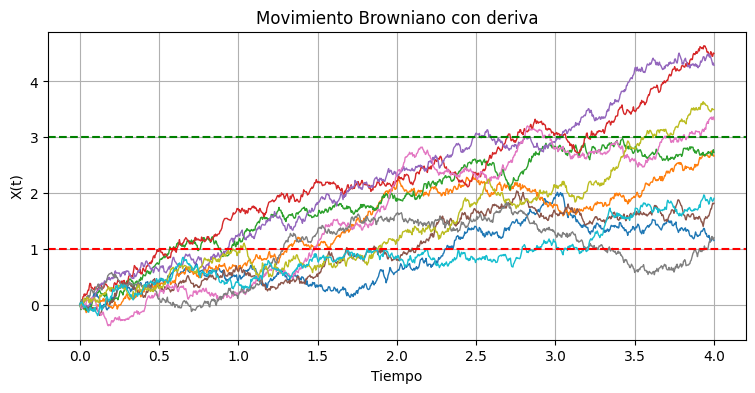

CON DERIVA
N = 20000 | M = 12902
Probabilidad simulada = 0.6451
Probabilidad analítica = 0.6449902230161554


In [ ]:
# Ejecutar ambas simulaciones
XT_con_deriva, P_con_deriva = deriva(mu, sigma, T, N)

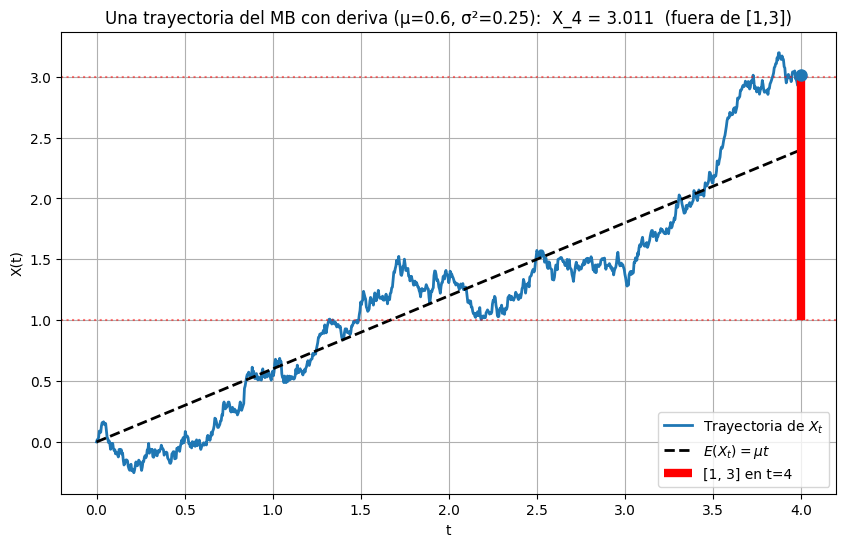

In [16]:
# Definimos las variables faltantes usando las equivalentes del entorno
t_obj = T
n_pasos = L
var = sigma**2

# Reemplazamos tiempos() por np.linspace
tt = np.linspace(0, t_obj, n_pasos + 1)

# Obtenemos la trayectoria usando la función 'deriva' (usamos n=1 caminata)
# Dado que 'deriva' retorna (XT, P) e imprime datos, simulamos directamente una trayectoria localmente
np.random.seed(42)  # Semilla para reproducibilidad
dt = t_obj / n_pasos
Z = np.random.normal(0, 1, n_pasos)
incrementos = mu * dt + sigma * np.sqrt(dt) * Z
X = np.zeros(n_pasos + 1)
X[1:] = np.cumsum(incrementos)

plt.figure(figsize=(10, 6))
plt.plot(tt, X, lw=2, label=r'Trayectoria de $X_t$')
plt.plot(tt, mu * tt, 'k--', lw=2, label=r'$E(X_t)=\mu t$')
plt.vlines(t_obj, a, b, color='red', lw=6, label=f'[{a}, {b}] en t={t_obj}')
plt.axhline(a, color='red', ls=':', alpha=0.5)
plt.axhline(b, color='red', ls=':', alpha=0.5)
plt.plot(t_obj, X[-1], 'o', color='C0', ms=8)

dentro = a < X[-1] < b
plt.title(f"Una trayectoria del MB con deriva (μ={mu}, σ²={var}):  X_4 = {X[-1]:.3f}  ({'dentro' if dentro else 'fuera'} de [{a},{b}])")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

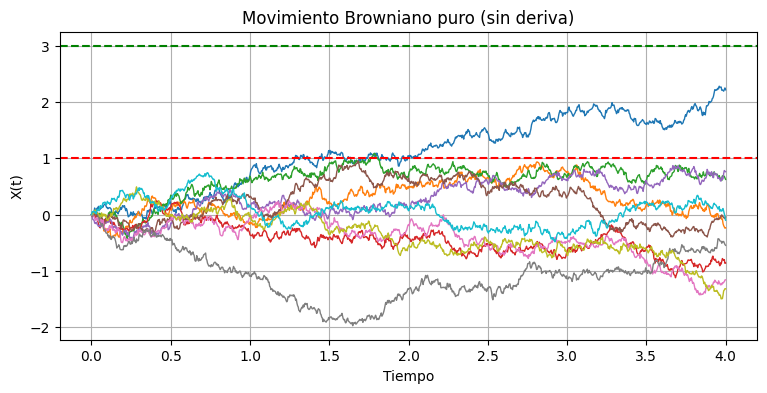

SIN DERIVA
N = 20000 | M = 3183
Probabilidad simulada = 0.15915
Probabilidad analítica = 0.15730535589982697


In [9]:
# Aseguramos que los parámetros estén definidos en el entorno
sigma = np.sqrt(0.25)
T = 4
N = 20000

XT_sin_deriva, P_sin_deriva = puro(sigma, T, N)

En este caso, el proceso no presenta una tendencia de crecimiento o disminución, ya que no existe deriva. Por lo tanto, las trayectorias se mueven de manera aleatoria alrededor de cero, y su dispersión depende del valor de $\sigma$ y del tiempo transcurrido.

Su media y varianza están dadas por:
$$
E[X_t]=0,\qquad \operatorname{Var}(X_t)=\sigma^2t
$$

Interpretación del intervalo $[1, 3]$$[1, 3]$ (Líneas punteadas)
Líneas límites: La línea roja punteada representa $y = 1$$y = 1$ y la verde representa $y = 3$$y = 3$.
Proporción de éxito (Probabilidad simulada): El valor de la probabilidad simulada (aproximadamente $15.91\%$$15.91\%$) representa la proporción de las $20,000$$20,000$ trayectorias totales que terminaron exactamente dentro de la franja comprendida entre ambas líneas al tiempo final $t=4$$t=4$.
Al ser un proceso sin deriva centrado en $0$$0$ y con desviación estándar $1$$1$ en $t=4$$t=4$, la mayor parte de las trayectorias finalizan cerca de $0$$0$. Por esta razón, el intervalo $[1, 3]$$[1, 3]$ queda desplazado hacia la derecha del promedio, capturando solo una pequeña porción del área total de la distribución (el $15.73\%$$15.73\%$ teórico).


In [11]:
# Definimos mu para solucionar el NameError
mu = 0.6
media = mu * T
desviacion = sigma * np.sqrt(T)

# Valores para la curva normal
x = np.linspace(media - 4*desviacion, media + 4*desviacion, 1000)
y = norm.pdf(x, loc=media, scale=desviacion)

# Probabilidad entre 1 y 3
a, b = 1, 3
probabilidad = (
    norm.cdf(b, loc=media, scale=desviacion)
    - norm.cdf(a, loc=media, scale=desviacion)
)

print("Media de la distribución:", media)
print("Desviación estándar:", desviacion)
print("Probabilidad analítica calculada:", probabilidad)

Media de la distribución: 2.4
Desviación estándar: 1.0
Probabilidad analítica calculada: 0.6449902230161554


## Conclusión

Con las simulaciones realizadas pudimos observar cómo se comporta el movimiento browniano en diferentes situaciones y cómo cambian sus trayectorias dependiendo de las condiciones que se le agreguen.

- **Movimiento browniano estándar:** observamos que todas las trayectorias comienzan en cero y que, conforme pasa el tiempo, se van separando cada vez más. Esto sucede porque su variabilidad aumenta con el tiempo. También vimos que sus movimientos son completamente aleatorios, por lo que no podemos saber con exactitud hacia dónde irá una trayectoria.

- **Refinamiento:** al aumentar el número de puntos de una trayectoria, pudimos ver con más detalle sus movimientos. Por ejemplo, al pasar de 100 a 200 puntos aparecen nuevas oscilaciones que antes no se apreciaban. Esto nos permitió observar que, aunque las trayectorias son continuas, tienen un comportamiento bastante irregular.

- **Puente browniano:** en este caso vimos algo diferente, ya que las trayectorias comienzan y terminan en cero. Lo interesante es que en la parte central del intervalo tienen mayor libertad para moverse, mientras que al acercarse al final todas regresan a cero. Esto también se refleja en su varianza, que alcanza su valor máximo en $t=0.5$.

- **Movimiento browniano puro sin deriva:** observamos que las trayectorias no siguen una tendencia definida, sino que se mueven aleatoriamente por encima y por debajo de cero. Por ejemplo, si tomamos $\sigma=0.5$ y $t=4$, obtenemos una media de cero y una varianza de uno. Esto no significa que todas las trayectorias terminen cerca de cero, sino que unas pueden terminar con valores positivos y otras con valores negativos.

- **Movimiento browniano con deriva:** a diferencia del anterior, aquí las trayectorias presentan una tendencia. En nuestro ejercicio utilizamos $\mu=0.6$ y $\sigma^2=0.25$, por lo que observamos que, aunque siguen existiendo movimientos aleatorios, las trayectorias tienden a crecer conforme pasa el tiempo. Para $t=4$, obtuvimos una media de $2.4$ y una varianza de $1$.

También pudimos comparar los resultados de las simulaciones con los valores teóricos. Al utilizar 100 trayectorias encontramos que los resultados pueden variar un poco cada vez que ejecutamos el programa, pero al aumentar el número de simulaciones generalmente obtenemos valores más cercanos a los esperados.

Por último, calculamos la probabilidad de que el movimiento browniano con deriva tome un valor entre $1$ y $3$ cuando $t=4$, obteniendo teóricamente:

$$
P(1<X_4<3)\approx 0.6450
$$

Esto significa que existe aproximadamente un **64.50 % de probabilidad** de que el proceso se encuentre dentro de ese intervalo. Con la simulación podemos obtener una estimación de esta probabilidad y comprobar qué tan cercana es al resultado teórico.

En general, estas prácticas nos ayudaron a entender mejor el comportamiento del movimiento browniano, ya que una cosa es conocer sus fórmulas y otra poder observar cómo se comportan las trayectorias. Además, pudimos ver que pequeños cambios en los parámetros pueden producir comportamientos diferentes y que las simulaciones son una buena herramienta para comprender y comprobar lo que estudiamos en la teoría.